# Data Exploration Report — Heupvervanging Chirurgie

Dit notebook bevat een verkennende data-analyse (exploratory data analysis) van de EPD-data en vragenlijstdata die worden gebruikt voor het dashboard over heupoperaties.

De data bestaat uit:
- **EPD-data**: patiëntgegevens, episodes of care (EOC), behandelingen, anesthesie en patiëntstatistieken (BMI, rookstatus, ASA-score).
- **Vragenlijstdata**: patiëntgerapporteerde uitkomsten op het gebied van pijn, mobiliteit en tevredenheid, 3 en 12 maanden na de interventie.

## 1. Bibliotheken importeren en configureren

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Visualisatie-instellingen ────────────────────────────────────────────────
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

# ── Paden naar de data-directories ──────────────────────────────────────────
# Het notebook staat in bp2/notebooks/; de data staat in bp2/data/
NOTEBOOK_DIR = os.path.dirname(os.path.abspath("__file__"))
DATA_DIR     = os.path.join(NOTEBOOK_DIR, "..", "..", "bp2", "data")
QUEST_DIR    = os.path.join(DATA_DIR, "questionnaires")

print("Data-directory:         ", os.path.abspath(DATA_DIR))
print("Questionnaire-directory:", os.path.abspath(QUEST_DIR))

Data-directory:          /Users/matthijs/gitrepos/Data-Engineer/bp2/data
Questionnaire-directory: /Users/matthijs/gitrepos/Data-Engineer/bp2/data/questionnaires


## 2. EPD-data inladen en NaN-overzicht

De EPD-data wordt ingeladen vanuit CSV-bestanden die dezelfde structuur hebben als de EPD-databasetabellen (zie `ddl_epd_bp2.sql`). Vervolgens wordt per tabel gecontroleerd hoeveel records aanwezig zijn en hoeveel NOT NULL-kolommen toch een NaN-waarde bevatten.

In [2]:
# ── Inladen van alle EPD-tabellen ────────────────────────────────────────────

patient = pd.read_csv(os.path.join(DATA_DIR, "patient.csv"), parse_dates=["dob"])

patient_statistic_type = pd.read_csv(os.path.join(DATA_DIR, "patient_statistic_type.csv"))

patient_statistic = pd.read_csv(
    os.path.join(DATA_DIR, "patient_statistic.csv"), parse_dates=["stat_ts"]
)

eoc = pd.read_csv(
    os.path.join(DATA_DIR, "eoc.csv"), parse_dates=["intake_date", "discharge_date"]
)

treatment_type = pd.read_csv(os.path.join(DATA_DIR, "treatment_type.csv"))

eoc_treatment = pd.read_csv(
    os.path.join(DATA_DIR, "eoc_treatment.csv"), parse_dates=["eoc_time"]
)
# is_primary is opgeslagen als integer (0/1); omzetten naar bool
eoc_treatment["is_primary"] = eoc_treatment["is_primary"].astype(bool)

eoc_treatment_anesthesia = pd.read_csv(
    os.path.join(DATA_DIR, "eoc_treatment_anesthesia.csv"),
    parse_dates=["anesthesia_time"],
)

hip_treatment_position = pd.read_csv(
    os.path.join(DATA_DIR, "hip_treatment_position.csv"),
    parse_dates=["position_time"],
)

# ── NOT NULL-kolommen per tabel, afgeleid uit ddl_epd_bp2.sql ────────────
# Alleen kolommen die in de DDL als NOT NULL zijn gedefinieerd worden gecontroleerd.
not_null_cols = {
    "patient":                    ["pid", "firstname", "lastname"],
    "patient_statistic_type":     ["stid", "stname", "sttype"],
    "patient_statistic":          ["pid", "stid"],
    "eoc":                        ["eocid", "pid", "intake_date"],
    "treatment_type":             ["tid", "tname"],
    "eoc_treatment":              ["eocid", "tid", "is_primary", "eoc_time"],
    "eoc_treatment_anesthesia":   ["eocid", "anesthesia_type", "anesthesia_time"],
    "hip_treatment_position":     ["eocid", "position_type", "position_time"],
}

tables = {
    "patient":                  patient,
    "patient_statistic_type":   patient_statistic_type,
    "patient_statistic":        patient_statistic,
    "eoc":                      eoc,
    "treatment_type":           treatment_type,
    "eoc_treatment":            eoc_treatment,
    "eoc_treatment_anesthesia": eoc_treatment_anesthesia,
    "hip_treatment_position":   hip_treatment_position,
}

# ── Overzichtstabel: records en NaN's in NOT NULL-kolommen ───────────────────
rows = []
for naam, df in tables.items():
    nan_in_notnull = sum(df[col].isna().sum() for col in not_null_cols[naam])
    rows.append({"Tabel": naam, "Records": len(df), "NaN in NOT NULL-kolommen": nan_in_notnull})

overzicht = pd.DataFrame(rows).set_index("Tabel")
print(overzicht.to_string())

                          Records  NaN in NOT NULL-kolommen
Tabel                                                      
patient                      3581                         0
patient_statistic_type          3                         0
patient_statistic           10743                         0
eoc                          3581                         0
treatment_type                  5                         0
eoc_treatment                4081                         0
eoc_treatment_anesthesia     4081                         0
hip_treatment_position       3581                         0


## 3. Patiëntdemografie

In deze sectie worden de demografische kenmerken van de patiënten gevisualiseerd op basis van de `patient`-tabel en de patiëntstatistieken (BMI, ASA-score, rookstatus).

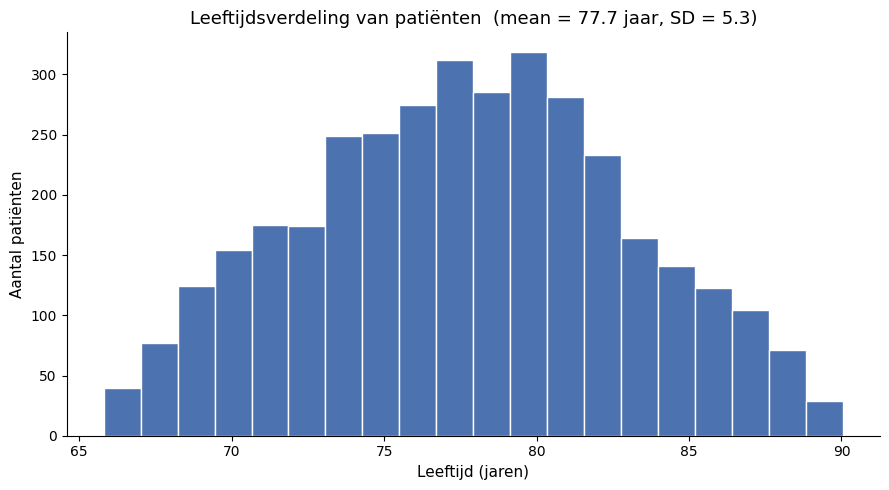

In [3]:
# ── Leeftijdsverdeling ───────────────────────────────────────────────────────

# Bereken leeftijd in jaren op basis van geboortedatum
patient["leeftijd"] = (pd.Timestamp.today() - patient["dob"]).dt.days / 365.25

leeftijd = patient["leeftijd"].dropna()
mu, sigma = leeftijd.mean(), leeftijd.std()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(leeftijd, bins=20, color="#4C72B0", edgecolor="white")
ax.set_title(f"Leeftijdsverdeling van patiënten  (mean = {mu:.1f} jaar, SD = {sigma:.1f})")
ax.set_xlabel("Leeftijd (jaren)")
ax.set_ylabel("Aantal patiënten")
plt.tight_layout()
plt.show()

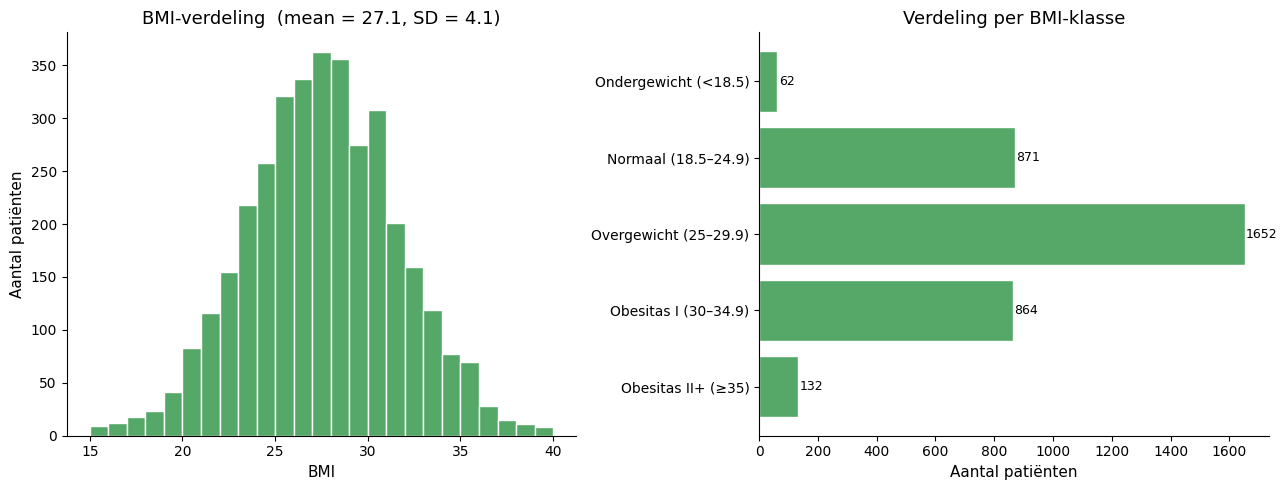

In [4]:
# ── BMI-verdeling: histogram en verdeling per BMI-klasse ─────────────────────

# Haal BMI-waarden op uit patient_statistic (stid = 1 = BMI)
bmi = (
    patient_statistic[patient_statistic["stid"] == 1][["pid", "stvalue_int"]]
    .rename(columns={"stvalue_int": "bmi"})
)

# Definieer BMI-klassen conform gangbare klinische indeling
bmi_bins   = [0, 18.5, 25, 30, 35, float("inf")]
bmi_labels = [
    "Ondergewicht (<18.5)",
    "Normaal (18.5–24.9)",
    "Overgewicht (25–29.9)",
    "Obesitas I (30–34.9)",
    "Obesitas II+ (≥35)",
]
bmi["bmi_klasse"] = pd.cut(bmi["bmi"], bins=bmi_bins, labels=bmi_labels, right=False)

bmi_vals = bmi["bmi"].dropna()
mu_bmi, sigma_bmi = bmi_vals.mean(), bmi_vals.std()
bmi_counts = bmi["bmi_klasse"].value_counts().reindex(bmi_labels)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Links: histogram van ruwe BMI-waarden
axes[0].hist(bmi_vals, bins=25, color="#55A868", edgecolor="white")
axes[0].set_title(f"BMI-verdeling  (mean = {mu_bmi:.1f}, SD = {sigma_bmi:.1f})")
axes[0].set_xlabel("BMI")
axes[0].set_ylabel("Aantal patiënten")

# Rechts: horizontaal staafdiagram per BMI-klasse
axes[1].barh(bmi_counts.index, bmi_counts.values, color="#55A868", edgecolor="white")
axes[1].set_title("Verdeling per BMI-klasse")
axes[1].set_xlabel("Aantal patiënten")
axes[1].invert_yaxis()  # grootste groep bovenaan
for i, v in enumerate(bmi_counts.values):
    axes[1].text(v + 5, i, str(v), va="center", fontsize=9)

plt.tight_layout()
plt.show()

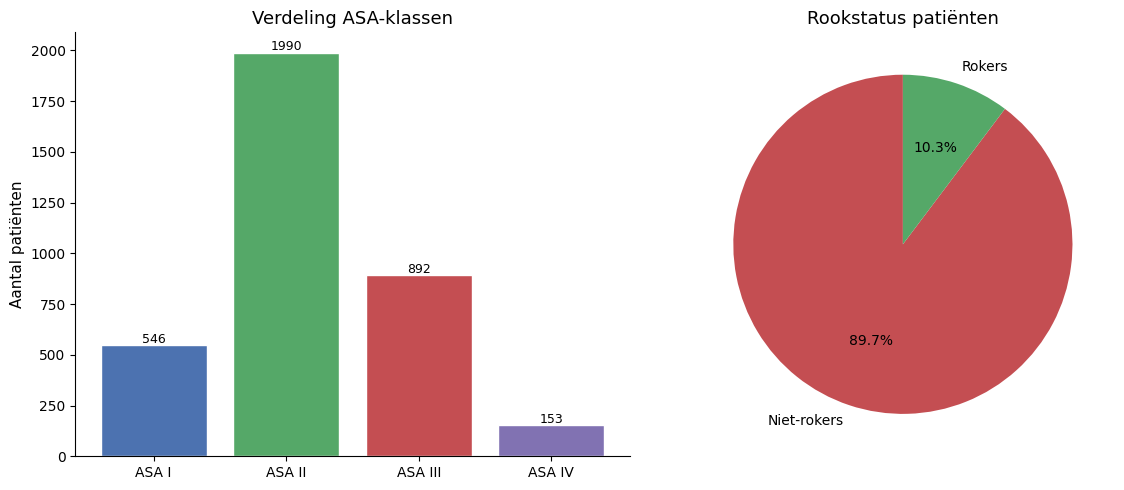

In [5]:
# ── ASA-klasse en rookstatus ─────────────────────────────────────────────────

# ASA-scores ophalen (stid = 3) en vertalen naar compacte klasse-labels
asa_raw = (
    patient_statistic[patient_statistic["stid"] == 3][["pid", "stvalue_string"]]
    .rename(columns={"stvalue_string": "asa_omschrijving"})
)
asa_map = {
    "healthy":
        "ASA I",
    "mild to moderate systemic abnormality that does not result in functional impairment":
        "ASA II",
    "Severe functionally limiting systemic abnormality":
        "ASA III",
    "systemic abnormality that poses a constant life-threatening danger":
        "ASA IV",
}
asa_raw["asa_klasse"] = asa_raw["asa_omschrijving"].map(asa_map)
asa_order = ["ASA I", "ASA II", "ASA III", "ASA IV"]
asa_counts = asa_raw["asa_klasse"].value_counts().reindex(asa_order)

# Rookstatus (stid = 2)
smoking_raw = (
    patient_statistic[patient_statistic["stid"] == 2][["pid", "stvalue_bool"]]
    .rename(columns={"stvalue_bool": "rooker"})
)
smoking_raw["rooker"] = smoking_raw["rooker"].map({1.0: "Rokers", 0.0: "Niet-rokers"})
smoking_counts = smoking_raw["rooker"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Links: staafdiagram ASA-klassen
axes[0].bar(asa_counts.index, asa_counts.values,
            color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"], edgecolor="white")
axes[0].set_title("Verdeling ASA-klassen")
axes[0].set_ylabel("Aantal patiënten")
for i, v in enumerate(asa_counts.values):
    axes[0].text(i, v + 10, str(v), ha="center", fontsize=9)

# Rechts: taartdiagram rookstatus
axes[1].pie(
    smoking_counts.values,
    labels=smoking_counts.index,
    autopct="%1.1f%%",
    colors=["#C44E52", "#55A868"],
    startangle=90,
)
axes[1].set_title("Rookstatus patiënten")

plt.tight_layout()
plt.show()

## 4. Operatiekarakteristieken

In deze sectie worden de primaire heupoperaties en reïnterventies geanalyseerd. Een reïnterventie is een niet-primaire behandeling (arthrotomy, revision partial, revision complete, reposition) die plaatsvindt binnen hetzelfde episode of care als een primaire heupoperatie.

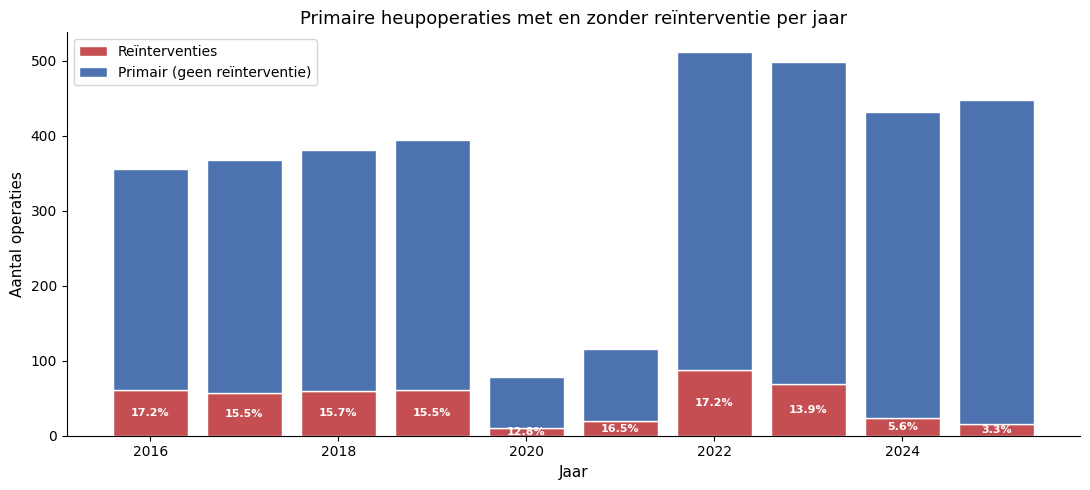

In [6]:
# ── Basisstructuur: primaire operaties en reïnterventies per jaar ─────────────

# Voeg behandelingsnaam en opnamejaar toe
treat = eoc_treatment.merge(treatment_type, on="tid", how="left")
treat = treat.merge(eoc[["eocid", "pid", "intake_date"]], on="eocid", how="left")
treat["jaar"] = treat["intake_date"].dt.year

# Typen behandelingen
PRIMAIR    = "hip replacement surgery"
REINT_NAMEN = ["arthrotomy", "revision (partial)", "revision (complete)", "reposition"]

# EOC's met een primaire heupoperatie
primaire_eoc = treat[treat["tname"] == PRIMAIR][["eocid", "jaar"]].drop_duplicates()

# EOC's die ook een reïnterventie hebben
reint_eoc = treat[treat["tname"].isin(REINT_NAMEN)][["eocid"]].drop_duplicates()
reint_eoc_set = set(reint_eoc["eocid"])

# Samenvatting per jaar: totaal primair en aantal met reïnterventie
primair_per_jaar = primaire_eoc.groupby("jaar").size().rename("primair")
reint_per_jaar = (
    primaire_eoc[primaire_eoc["eocid"].isin(reint_eoc_set)]
    .groupby("jaar").size()
    .rename("reinterventie")
)

samenvatting = pd.concat([primair_per_jaar, reint_per_jaar], axis=1).fillna(0).astype(int)
samenvatting["pct"] = (samenvatting["reinterventie"] / samenvatting["primair"] * 100).round(1)

# ── Gestapeld staafdiagram: % reïnterventies per jaar ────────────────────────
# Onderste segment = reïnterventies; bovenste segment = primair zonder reïnterventie
fig, ax = plt.subplots(figsize=(11, 5))
jaren = samenvatting.index
geen_reint = samenvatting["primair"] - samenvatting["reinterventie"]

ax.bar(jaren, samenvatting["reinterventie"],
       label="Reïnterventies", color="#C44E52", edgecolor="white")
ax.bar(jaren, geen_reint, bottom=samenvatting["reinterventie"],
       label="Primair (geen reïnterventie)", color="#4C72B0", edgecolor="white")

# Percentagelabel midden in het onderste segment
for jaar in jaren:
    reint = samenvatting.loc[jaar, "reinterventie"]
    pct   = samenvatting.loc[jaar, "pct"]
    if reint > 0:
        ax.text(jaar, reint / 2, f"{pct}%",
                ha="center", va="center", color="white", fontsize=8, fontweight="bold")

ax.set_title("Primaire heupoperaties met en zonder reïnterventie per jaar")
ax.set_xlabel("Jaar")
ax.set_ylabel("Aantal operaties")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.legend()
plt.tight_layout()
plt.show()

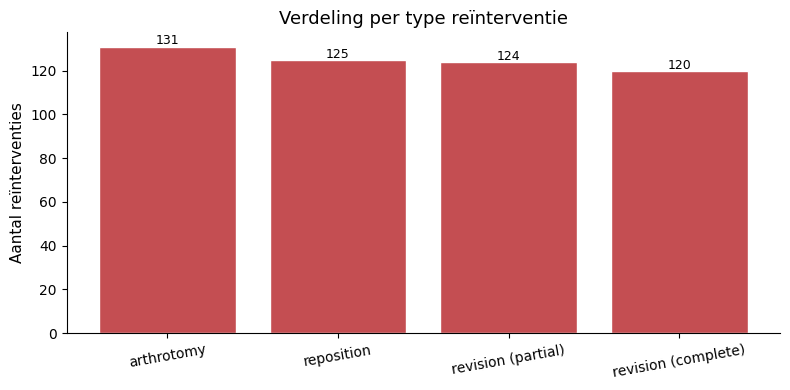

In [7]:
# ── Verdeling per type reïnterventie ─────────────────────────────────────────

reint_type_counts = (
    treat[treat["tname"].isin(REINT_NAMEN)]["tname"]
    .value_counts()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(reint_type_counts.index, reint_type_counts.values, color="#C44E52", edgecolor="white")
ax.set_title("Verdeling per type reïnterventie")
ax.set_ylabel("Aantal reïnterventies")
ax.tick_params(axis="x", rotation=10)
for i, v in enumerate(reint_type_counts.values):
    ax.text(i, v + 1, str(v), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
# ── Tabel: jaar | primaire operaties | reïnterventies | % ────────────────────

tabel = samenvatting.copy()
tabel.index.name = "Jaar"
tabel.columns = ["Primaire operaties", "Reïnterventies", "% Reïnterventies"]
print(tabel.to_string())

      Primaire operaties  Reïnterventies  % Reïnterventies
Jaar                                                      
2016                 355              61              17.2
2017                 368              57              15.5
2018                 381              60              15.7
2019                 394              61              15.5
2020                  78              10              12.8
2021                 115              19              16.5
2022                 512              88              17.2
2023                 498              69              13.9
2024                 432              24               5.6
2025                 448              15               3.3


## 5. Aanvullende operatiekarakteristieken

In deze sectie worden het type anesthesie en het type operatiepositie (chirurgische benadering) geanalyseerd. De operatiepositie fungeert in deze dataset als proxy voor de gebruikte prothese-benadering, omdat er geen afzonderlijke prothese-typetabel aanwezig is in de EPD-data.

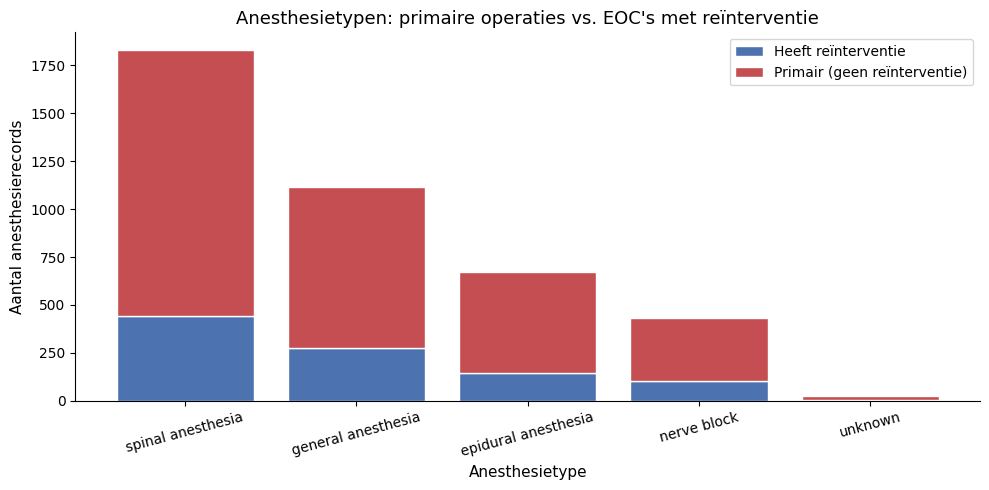

In [9]:
# ── Anesthesie: gestapeld staafdiagram (primair vs. reïnterventie) ────────────
# Per anesthesietype: hoeveel EOC's met alleen primaire operatie vs. met reïnterventie

# Classificeer elk EOC als 'heeft reïnterventie' of niet
eta = eoc_treatment_anesthesia.copy()
eta["heeft_reint"] = eta["eocid"].isin(reint_eoc_set)
eta["categorie"] = eta["heeft_reint"].map({False: "Primair (geen reïnterventie)", True: "Heeft reïnterventie"})

# Tel per anesthesietype en categorie
anest_pivot = (
    eta.groupby(["anesthesia_type", "categorie"])
    .size()
    .unstack(fill_value=0)
)

# Volgorde op totale grootte
anest_pivot = anest_pivot.loc[anest_pivot.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(anest_pivot))
colors = ["#4C72B0", "#C44E52"]

for kolom, kleur in zip(anest_pivot.columns, colors):
    vals = anest_pivot[kolom].values
    ax.bar(anest_pivot.index, vals, bottom=bottom, label=kolom, color=kleur, edgecolor="white")
    bottom += vals

ax.set_title("Anesthesietypen: primaire operaties vs. EOC's met reïnterventie")
ax.set_xlabel("Anesthesietype")
ax.set_ylabel("Aantal anesthesierecords")
ax.tick_params(axis="x", rotation=15)
ax.legend()
plt.tight_layout()
plt.show()

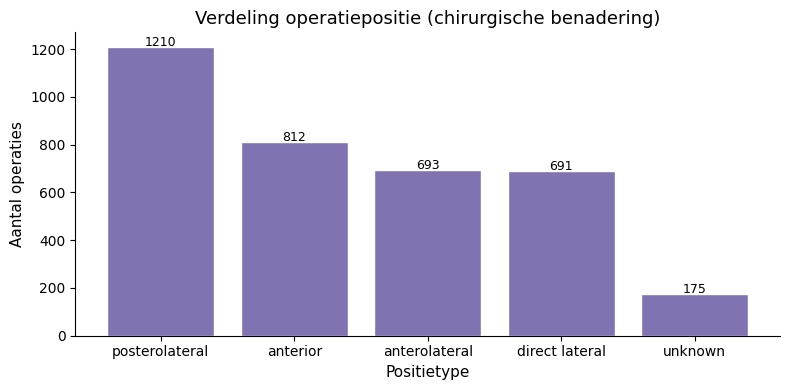

In [10]:
# ── Operatiepositie (chirurgische benadering / prothese-benadering) ───────────
# De hip_treatment_position-tabel slaat de chirurgische positie op per EOC.
# Dit is de dichtstbijzijnde proxy voor prothese-benadering in de huidige dataset.

pos_counts = (
    hip_treatment_position["position_type"]
    .value_counts()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pos_counts.index, pos_counts.values, color="#8172B2", edgecolor="white")
ax.set_title("Verdeling operatiepositie (chirurgische benadering)")
ax.set_xlabel("Positietype")
ax.set_ylabel("Aantal operaties")
for i, v in enumerate(pos_counts.values):
    ax.text(i, v + 5, str(v), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 6. Verpleegdagen (length of stay)

In deze sectie wordt de opnameduur geanalyseerd voor patiënten die een primaire heupoperatie hebben ondergaan. De grens van 5 dagen is relevant voor KPI6.

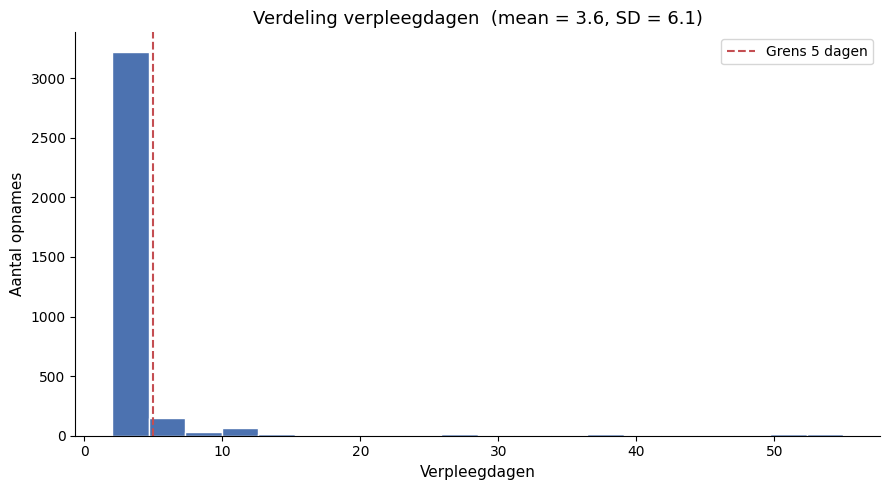

In [11]:
# ── Verpleegdagen berekenen voor EOC's met een primaire heupoperatie ──────────

# Filter op EOC's die een primaire heupoperatie hebben
primaire_eocids = set(primaire_eoc["eocid"])
eoc_primair = eoc[eoc["eocid"].isin(primaire_eocids)].copy()
eoc_primair["verpleegdagen"] = (
    eoc_primair["discharge_date"] - eoc_primair["intake_date"]
).dt.days
eoc_primair["jaar"] = eoc_primair["intake_date"].dt.year

los = eoc_primair["verpleegdagen"].dropna()
mu_los, sigma_los = los.mean(), los.std()

# ── Histogram van verpleegdagen ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(los, bins=20, color="#4C72B0", edgecolor="white")
ax.axvline(5, color="#C44E52", linestyle="--", label="Grens 5 dagen")
ax.set_title(f"Verdeling verpleegdagen  (mean = {mu_los:.1f}, SD = {sigma_los:.1f})")
ax.set_xlabel("Verpleegdagen")
ax.set_ylabel("Aantal opnames")
ax.legend()
plt.tight_layout()
plt.show()

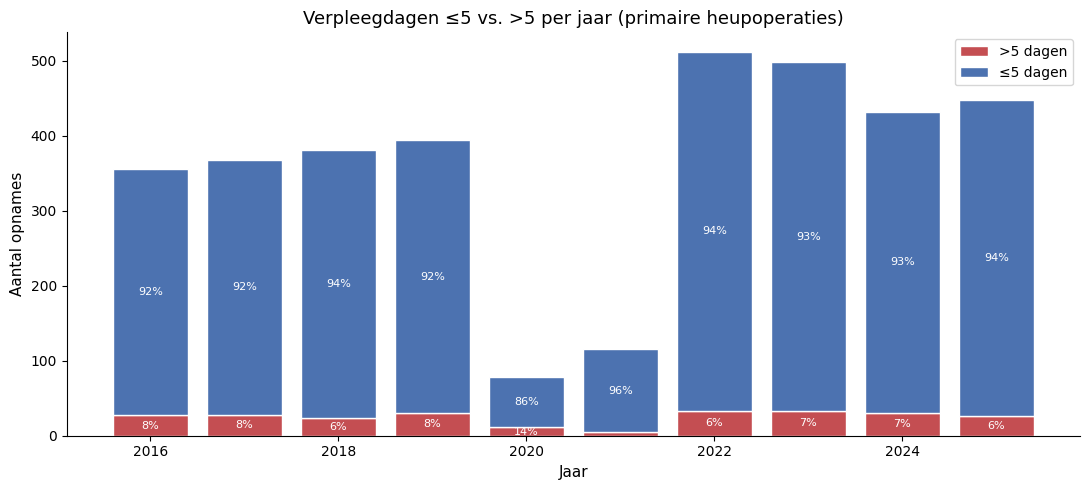

In [12]:
# ── Gestapeld staafdiagram: ≤5 vs. >5 verpleegdagen per jaar ─────────────────
# Elke balk toont het totale aantal primaire operaties in dat jaar.
# Het onderste segment = patiënten met >5 dagen; het bovenste = ≤5 dagen.

eoc_primair["los_cat"] = eoc_primair["verpleegdagen"].apply(
    lambda d: "≤5 dagen" if d <= 5 else ">5 dagen"
)

los_pivot = (
    eoc_primair.groupby(["jaar", "los_cat"])
    .size()
    .unstack(fill_value=0)
    # Zorg dat beide categorieën aanwezig zijn
    .reindex(columns=[">5 dagen", "≤5 dagen"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(los_pivot))

for kolom, kleur, label in [
    (">5 dagen",  "#C44E52", ">5 dagen"),
    ("≤5 dagen",  "#4C72B0", "≤5 dagen"),
]:
    vals = los_pivot[kolom].values
    bars = ax.bar(los_pivot.index, vals, bottom=bottom, label=label,
                  color=kleur, edgecolor="white")
    # Percentagelabel midden in elk segment (alleen bij voldoende hoogte)
    for rect, v, tot in zip(bars, vals, los_pivot.sum(axis=1).values):
        pct = v / tot * 100
        if v > 5:
            ax.text(
                rect.get_x() + rect.get_width() / 2,
                rect.get_y() + rect.get_height() / 2,
                f"{pct:.0f}%",
                ha="center", va="center", color="white", fontsize=8,
            )
    bottom += vals

ax.set_title("Verpleegdagen ≤5 vs. >5 per jaar (primaire heupoperaties)")
ax.set_xlabel("Jaar")
ax.set_ylabel("Aantal opnames")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.legend()
plt.tight_layout()
plt.show()

## 7. Vragenlijstdata

De vragenlijstdata bestaat uit `.resp`-bestanden, één per patiënt (`<pid>.resp`). Elk bestand bevat scores op de volgende drie categorieën:

| Categorie | Velden |
|---|---|
| Pijn | Verandering in pijn na 3 en 12 maanden (score 1–10) |
| Mobiliteit | Dagelijks functioneren na 3 en 12 maanden (score 1–10) |
| Tevredenheid | Tevredenheid resultaat na 3 en 12 maanden (score 1–10) |

In [13]:
# ── Inlezen van alle .resp vragenlijstbestanden ──────────────────────────────

def parse_resp_file(filepath: str, pid: int) -> dict:
    """
    Lees één .resp-bestand in en retourneer een dictionary met de pid
    en alle sleutel-waarde-paren als numerieke waarden.
    """
    record = {"pid": pid}
    with open(filepath, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if ":" not in line:
                continue
            key, value = line.split(":", 1)
            try:
                record[key.strip()] = float(value.strip())
            except ValueError:
                pass
    return record

records = []
for fname in os.listdir(QUEST_DIR):
    if not fname.endswith(".resp"):
        continue
    pid_val = int(fname.replace(".resp", ""))
    records.append(parse_resp_file(os.path.join(QUEST_DIR, fname), pid_val))

questionnaire = pd.DataFrame(records).rename(columns={
    "Dagelijks functioneren na 3 maanden":  "mobiliteit_3m",
    "Dagelijks functioneren na 12 maanden": "mobiliteit_12m",
    "Tevredenheid resultaat na 3 maanden":  "tevredenheid_3m",
    "Tevredenheid resultaat na 12 maanden": "tevredenheid_12m",
    "Verandering in pijn na 3 maanden":     "pijn_3m",
    "Verandering in pijn na 12 maanden":    "pijn_12m",
})

# ── Koppel elke patiënt aan het jaar van zijn primaire operatie ───────────────
primaire_jaar = (
    eoc_primair[["eocid", "jaar"]]
    .merge(primaire_eoc[["eocid"]], on="eocid")
    .merge(eoc[["eocid", "pid"]], on="eocid")
    .groupby("pid")["jaar"].min()
    .reset_index()
)

# ── Tabel: jaar | primaire behandelingen | responses | % ─────────────────────
main_per_jaar   = primaire_jaar.groupby("jaar").size().rename("Primaire behandelingen")
quest_jaar      = questionnaire[["pid"]].merge(primaire_jaar, on="pid", how="left")
resp_per_jaar   = quest_jaar.groupby("jaar").size().rename("Vragenlijsten")

resp_tabel = pd.concat([main_per_jaar, resp_per_jaar], axis=1).fillna(0).astype(int)
resp_tabel["% Respons"] = (
    resp_tabel["Vragenlijsten"] / resp_tabel["Primaire behandelingen"] * 100
).round(1)
resp_tabel.index.name = "Jaar"

print(f"Totaal ingeladen vragenlijsten: {len(questionnaire)}\n")
print(resp_tabel.to_string())

Totaal ingeladen vragenlijsten: 2865

      Primaire behandelingen  Vragenlijsten  % Respons
Jaar                                                  
2016                     355            298       83.9
2017                     368            295       80.2
2018                     381            302       79.3
2019                     394            315       79.9
2020                      78             61       78.2
2021                     115             87       75.7
2022                     512            420       82.0
2023                     498            407       81.7
2024                     432            330       76.4
2025                     448            350       78.1


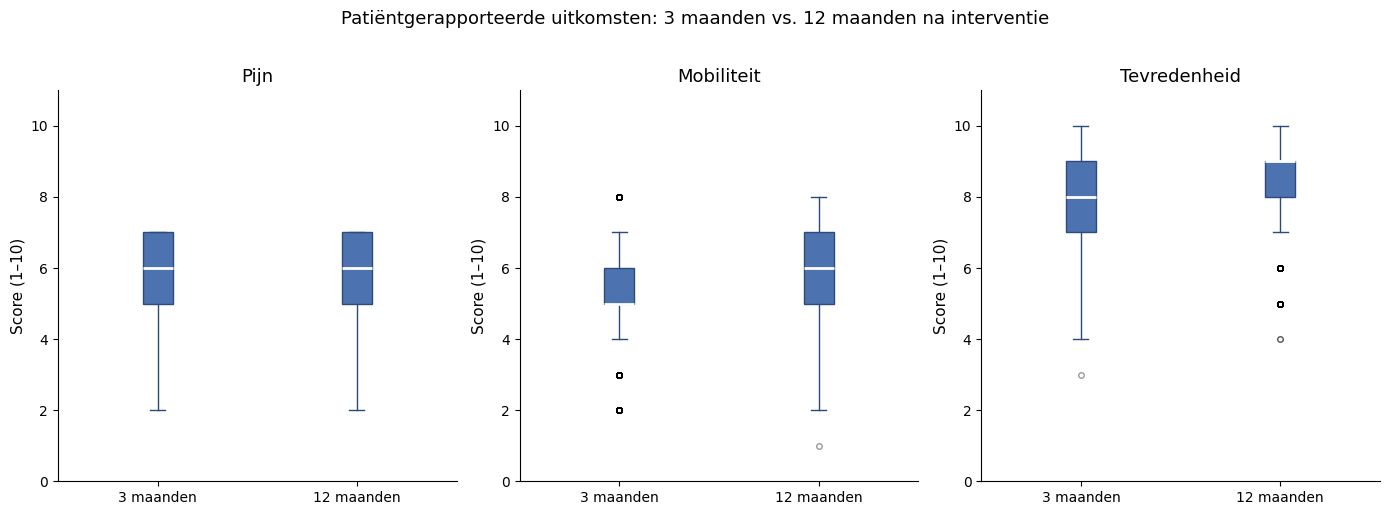

In [14]:
# ── Box plots: pijn, mobiliteit en tevredenheid (3m vs. 12m) ─────────────────
# Per categorie twee boxes naast elkaar: score na 3 maanden en score na 12 maanden.

categorieen = [
    ("pijn_3m",        "pijn_12m",        "Pijn"),
    ("mobiliteit_3m",  "mobiliteit_12m",  "Mobiliteit"),
    ("tevredenheid_3m","tevredenheid_12m", "Tevredenheid"),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, (col_3m, col_12m, titel) in zip(axes, categorieen):
    ax.boxplot(
        [questionnaire[col_3m].dropna(), questionnaire[col_12m].dropna()],
        tick_labels=["3 maanden", "12 maanden"],
        patch_artist=True,
        boxprops=dict(facecolor="#4C72B0", color="#2d4a7a"),
        medianprops=dict(color="white", linewidth=2),
        whiskerprops=dict(color="#2d4a7a"),
        capprops=dict(color="#2d4a7a"),
        flierprops=dict(marker="o", markersize=4, alpha=0.4),
    )
    ax.set_title(titel)
    ax.set_ylabel("Score (1–10)")
    ax.set_ylim(0, 11)

plt.suptitle(
    "Patiëntgerapporteerde uitkomsten: 3 maanden vs. 12 maanden na interventie",
    fontsize=13, y=1.02,
)
plt.tight_layout()
plt.show()